In [ ]:
from engine.utils import l2_normalise, get_rabit
from engine.rabitq import get_rabit
from engine.evp import get_evp_row_arg_partition_stable

from move import move_on_unit_sphere

import numpy as np
from tqdm import tqdm
from matplotlib import pyplot as plt

In [2]:
def get_next_normed_random_vec( d: int ) -> np.array:
    """
    :param d: the number of dimensions required
    :return: a l2 normed random vector of dimension d and
    """
    return l2_normalise(np.random.normal(0, 1, (d,)))

In [3]:
from move import move_on_unit_sphere, get_random_orthogonal_vector

def rotate(vector: np.array, angle: float):
    old_evp = get_evp_row_arg_partition_stable(vector)
    old_rabit = get_rabit(vector)

    evp_change = []
    rabit_change = []

    evp_change_count = 0
    rabit_change_count = 0

    cumulative_angle_changes = []
    direction = get_random_orthogonal_vector(vector)

    np.set_printoptions(precision=10, suppress=False, linewidth=np.inf)

    for i in tqdm(range(int((np.pi / 4) / angle))):
        cumulative_angle_changes.append(i * angle)

        angle_to_move = i * angle
        moved_vector = move_on_unit_sphere(vector, direction, angle_to_move)             # Generate the moved vector

        evp = get_evp_row_arg_partition_stable(moved_vector)
        rabit = get_rabit(moved_vector)

        if not np.array_equal(old_evp, evp):
            # evp_change.append(i)
            evp_change_count += 1
        if not np.array_equal(old_rabit, rabit):
            # rabit_change.append(i)
            rabit_change_count += 1

        evp_change.append(evp_change_count)
        rabit_change.append(rabit_change_count)

        old_evp = evp
        old_rabit = rabit

    return cumulative_angle_changes, evp_change, rabit_change


In [4]:
badvec = np.array([-1.6357144286e-02, 3.7649190363e-02 -6.8222883194e-04 -3.8967579292e-02, 9.0664052631e-03 -1.6881179304e-02 -5.2543342314e-02, 1.9572670779e-01 -8.7530678290e-03, 2.0029872779e-02, 4.5998846546e-02, 5.9366023572e-02 -3.5426487368e-02, 7.3499296312e-03 -7.4342583701e-02, 5.4718062614e-02, 3.6081231566e-02, 1.0370044995e-02 -1.2189393584e-01, 4.9597439196e-02, 9.2524159767e-03 -1.6818933160e-01, 6.8765996541e-02, 1.2922436366e-01 -4.2128164328e-02 -1.4871937179e-01, 7.3447959536e-02, 1.5400047114e-02, 2.5229555381e-01 -1.0056101239e-01 -2.7811135611e-02, 6.6604573523e-02 -5.7499919791e-02 -6.0434767487e-02 -1.1848817011e-01 -1.9689294983e-01, 1.5114941622e-01, 5.5914588290e-02 -1.2997274755e-01 -1.6519805159e-01, 1.4558544901e-01 -1.4672367962e-02, 1.0120895547e-01 -5.9945373379e-03 -1.2360686100e-02, 7.1628552969e-03 -6.1982671428e-02, 4.9329465490e-02 -9.3318357275e-02 -2.5354246065e-03 -2.9367732942e-01, 6.6693939015e-02, 1.3288832006e-02 -1.5588186450e-01 -4.4503343051e-02 -1.2022484366e-01 -1.6267419218e-02, 3.9733108266e-02 -1.1484373993e-01 -3.6678443044e-02 -1.6167829112e-01, 1.2830253905e-01, 1.8845413597e-02 -8.6614637219e-02, 1.9883863344e-02, 2.8105621708e-01 -7.3602827133e-02 -5.6629981411e-03 -6.1488079781e-02 -1.7452885922e-01 -4.5539847806e-02, 1.5350586208e-01 -8.5369371856e-02 -6.1145127886e-02 -8.6739860202e-02, 1.0500593782e-01 -1.5497485629e-02 -3.6921438783e-02, 5.2315858383e-02 -5.0080695940e-02, 5.1941077595e-02, 1.2436849289e-01 -2.5895826547e-02, 2.5279979836e-02, 2.0319017887e-01 -1.6942714979e-01, 1.2870248494e-01 -2.4791681021e-04 -2.0745567470e-01, 3.8821720712e-03 -4.1173417835e-02 -2.5627741675e-02 -6.0967688637e-02 -5.3368196554e-02 -2.8995524507e-02, 2.2058507987e-02, 3.8335298401e-02 -9.7813001067e-03, 1.7484041910e-01, 1.2055373680e-01])

In [19]:
dims = 800
angle = 0.001
vec = get_next_normed_random_vec(dims)
cumulative_angle_changes, evp_change, rabit_change = rotate(vec, angle)




100%|██████████| 785/785 [00:36<00:00, 21.39it/s]


Text(0.5, 1.0, 'Evp vs rabbit node changes for 800 dimensions and angle 0.001')

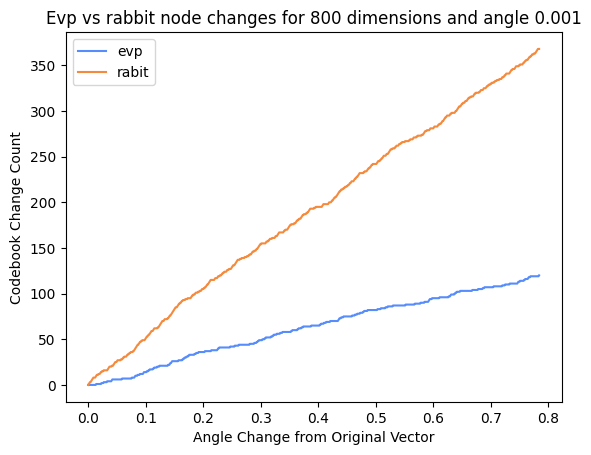

In [23]:
plt.plot(cumulative_angle_changes, evp_change,label = "evp")
plt.plot(cumulative_angle_changes, rabit_change,label = "rabit")
plt.xlabel("Angle Change from Original Vector")
plt.ylabel("Codebook Change Count")
plt.legend()
plt.title(f'Evp vs rabbit node changes for {dims} dimensions and angle {angle}')

In [24]:
dims = 1000
angle = 0.001

evp_changes = []
rabit_changes = []

loops = 25

for i in range(loops):
    vec = get_next_normed_random_vec(dims)
    cumulative_angle_changes, evp_change, rabit_change = rotate(vec, angle)
    evp_changes.append(evp_change)
    rabit_changes.append(rabit_change)


100%|██████████| 785/785 [00:43<00:00, 18.09it/s]


/var/folders/r3/fw58dm0n5519m62_fcx5l7sc0000gq/T/ipykernel_14809/4140613949.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 1.0, 'Angle Changes vs EVP Node Changes: 1000 dimensions, angle 0.001, and 25 loops')

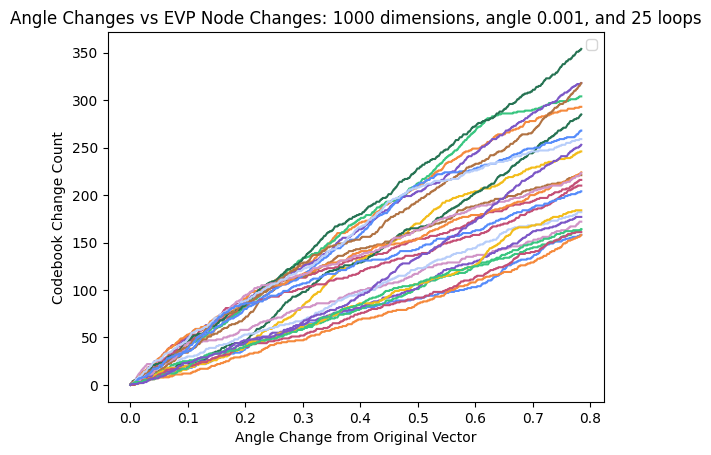

In [25]:
for li in evp_changes:
    plt.plot(cumulative_angle_changes, li)

plt.xlabel("Angle Change from Original Vector")
plt.ylabel("Codebook Change Count")
plt.legend()
plt.title(f'Angle Changes vs EVP Node Changes: {dims} dimensions, angle {angle}, and {loops} loops')

/var/folders/r3/fw58dm0n5519m62_fcx5l7sc0000gq/T/ipykernel_14809/1237763579.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 1.0, 'Angle Changes vs Rabit Codebook Changes: 1000 dimensions, angle 0.001, and 25 loops')

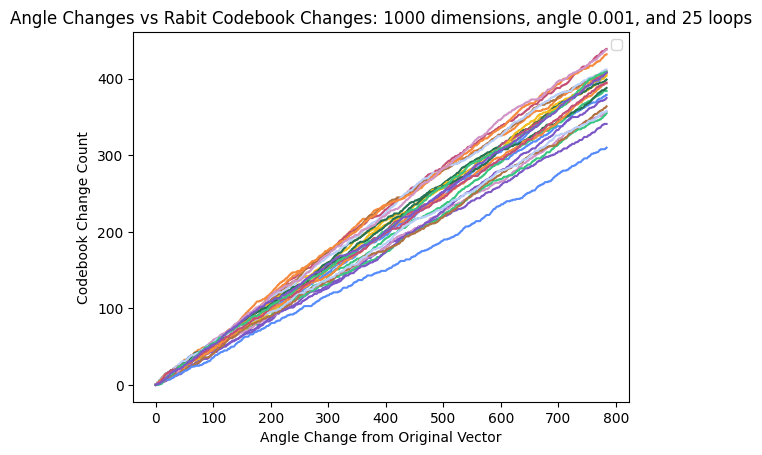

In [26]:
for li in rabit_changes:
    plt.plot(li)

plt.xlabel("Angle Change from Original Vector")
plt.ylabel("Codebook Change Count")
plt.legend()
plt.title(f'Angle Changes vs Rabit Codebook Changes: {dims} dimensions, angle {angle}, and {loops} loops')

In [27]:
from move import move_on_unit_sphere, get_random_orthogonal_vector

def rotate_through_random_direction(vector: np.array, angle: float):
    old_evp = get_evp_row_arg_partition_stable(vector)
    old_rabit = get_rabit(vector)

    evp_change = []
    rabit_change = []

    evp_change_count = 0
    rabit_change_count = 0

    cumulative_angle_changes = []
    direction = get_random_orthogonal_vector(vector)

    np.set_printoptions(precision=10, suppress=False, linewidth=np.inf)

    for i in tqdm(range(int((np.pi / 4) / angle))):
        cumulative_angle_changes.append(i * angle)

        angle_to_move = i * angle
        moved_vector = move_on_unit_sphere(vector, direction, angle_to_move)             # Generate the moved vector

        evp = get_evp_row_arg_partition_stable(moved_vector)
        rabit = get_rabit(moved_vector)

        if not np.array_equal(old_evp, evp):
            # evp_change.append(i)
            evp_change_count += 1
        if not np.array_equal(old_rabit, rabit):
            # rabit_change.append(i)
            rabit_change_count += 1

        evp_change.append(evp_change_count)
        rabit_change.append(rabit_change_count)

        old_evp = evp
        old_rabit = rabit

    return cumulative_angle_changes, evp_change, rabit_change


In [30]:
dims = 1000
angle = 0.001

evp_changes = []
rabit_changes = []

loops = 10

vec = get_next_normed_random_vec(dims)

for i in range(loops):
    cumulative_angle_changes, evp_change, rabit_change = rotate_through_random_direction(vec, angle)
    evp_changes.append(evp_change)
    rabit_changes.append(rabit_change)


100%|██████████| 785/785 [00:39<00:00, 19.71it/s]


Text(0.5, 1.0, 'EVP Angle Changes vs Codebook Changes. Rotating Random Direction from Single Vector: 1000 dimensions, angle 0.001, and 10 loops')

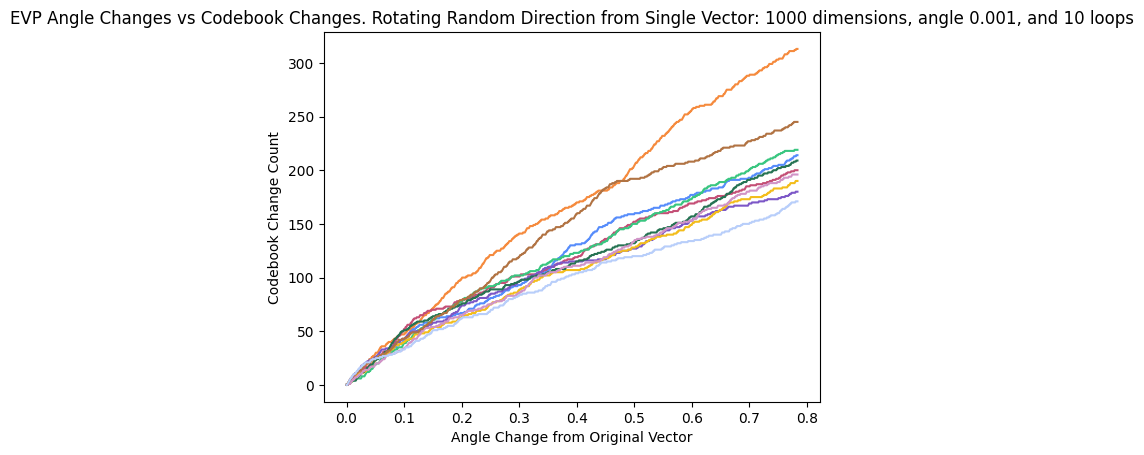

In [31]:
for li in evp_changes:
    plt.plot(cumulative_angle_changes, li)

plt.xlabel("Angle Change from Original Vector")
plt.ylabel("Codebook Change Count")
plt.title(f'EVP Angle Changes vs Codebook Changes. Rotating Random Direction from Single Vector: {dims} dimensions, angle {angle}, and {loops} loops')

Text(0.5, 1.0, 'Rabit Angle Changes vs Codebook Changes. Rotating Random Direction from Single Vector: 1000 dimensions, angle 0.001, and 10 loops')

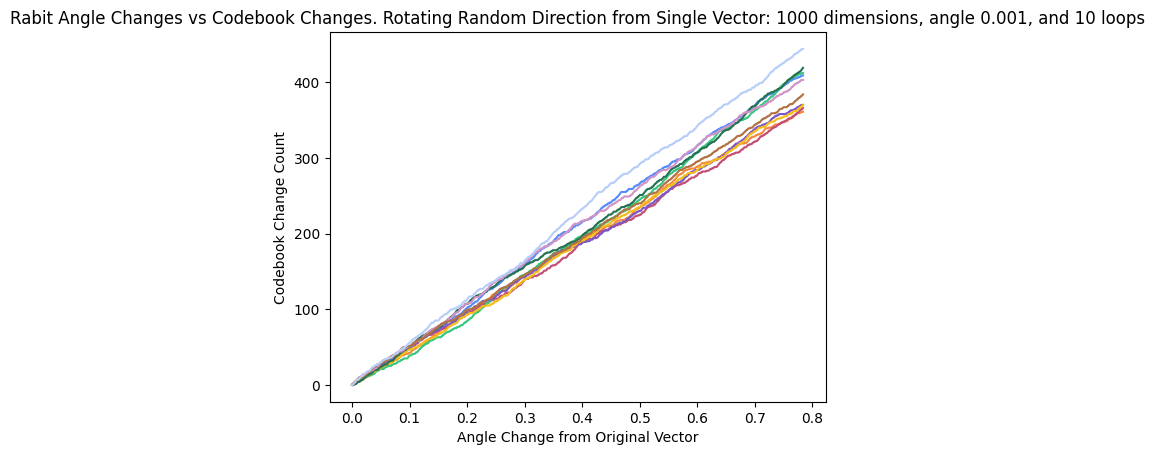

In [32]:
for li in rabit_changes:
    plt.plot(cumulative_angle_changes, li)

plt.xlabel("Angle Change from Original Vector")
plt.ylabel("Codebook Change Count")
plt.title(f'Rabit Angle Changes vs Codebook Changes. Rotating Random Direction from Single Vector: {dims} dimensions, angle {angle}, and {loops} loops')